# 03 U-Net (Lab 9 + Assignment 6)

Segment buildings, trees, and open ground.

**Inputs**
- `data/raw/6950/naip/`
- `data/raw/6950/labels/`
- `musa6950/unet.py` (plain U-Net in torch, same idea as the Assignment 6 UNET class)

**Output**
- `data/models/unet.pt` (not committed) + `data/models/unet_train_log.csv`
- `data/processed/6950_metrics_unet.json`
- `docs/figures/03_training_curve.png`, `03_example_prediction.png`, `03_unet_confusion.png`

Run `python musa6950/get_data.py` first. Use the geoai env.

In [1]:
import sys
import json
import time
from pathlib import Path
import numpy as np
import pandas as pd
import geopandas as gpd
import rasterio
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

ROOT = Path.cwd().parents[1] if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "shared"))
sys.path.insert(0, str(ROOT / "musa6950"))
from common import RAW, OUT
R6 = RAW / "6950"
FIG = ROOT / "musa6950" / "docs" / "figures"
MODELS = ROOT / "data" / "models"
MODELS.mkdir(parents=True, exist_ok=True)
boxes = gpd.read_file(R6 / "sample_boxes.gpkg")
have = boxes.GEOID.map(lambda g: (R6 / "naip" / f"{g}.tif").exists() and (R6 / "labels" / f"{g}.tif").exists())
boxes = boxes[have].reset_index(drop=True)   # 4 boxes on the NY line have no 2022 PA image
boxes.groupby(["split", "stratum"]).size()

split  stratum 
test   rural        7
       suburban    10
       urban       10
train  rural       47
       suburban    49
       urban       50
dtype: int64

## Validation split

- Hold back whole train counties (seed 42) until about 15% of train boxes are held back
- Test = Cumberland + Centre, never seen in training

In [2]:
rng = np.random.default_rng(42)
train_counties = boxes[boxes.split == "train"].county.unique()
order = rng.permutation(train_counties)
val_counties, n = [], 0
target = int(0.15 * (boxes.split == "train").sum())
for c in order:
    if n >= target:
        break
    val_counties.append(c); n += (boxes.county == c).sum()
boxes["role"] = np.where(boxes.split == "test", "test", np.where(boxes.county.isin(val_counties), "val", "train"))
print("val counties:", sorted(val_counties))
print(boxes.groupby(["role", "stratum"]).size().unstack())

val counties: ['42001', '42009', '42011', '42021', '42099', '42109', '42117']
stratum  rural  suburban  urban
role                           
test         7        10     10
train       40        39     43
val          7        10      7


## Tiles

- 256 x 256 tiles from each box
- Drop tiles that are mostly 255

In [3]:
T = 256


def load(geoid):
    with rasterio.open(R6 / "naip" / f"{geoid}.tif") as s:
        img = s.read()
    with rasterio.open(R6 / "labels" / f"{geoid}.tif") as s:
        lab = s.read(1)
    return img, lab


def tiles(img, lab):
    _, H, W = img.shape
    out_x, out_y = [], []
    for i in range(0, H - T + 1, T):
        for j in range(0, W - T + 1, T):
            y = lab[i:i + T, j:j + T]
            if (y == 255).mean() > 0.5:
                continue
            out_x.append(img[:, i:i + T, j:j + T]); out_y.append(y)
    return out_x, out_y


data = {}
for role in ["train", "val"]:
    xs, ys = [], []
    for g in boxes[boxes.role == role].GEOID:
        a, b = tiles(*load(g))
        xs += a; ys += b
    data[role] = (np.stack(xs), np.stack(ys))
    print(role, data[role][0].shape)

Xtr, Ytr = data["train"]
mean = Xtr.reshape(len(Xtr), 4, -1).mean(axis=(0, 2)).astype(np.float32)
std = Xtr[::20].reshape(-1, 4, T * T).transpose(1, 0, 2).reshape(4, -1).std(axis=1).astype(np.float32)
freq = np.bincount(Ytr.ravel(), minlength=256)[:4].astype(float)
freq /= freq.sum()
w = 1 / np.sqrt(freq)
class_weights = (w / w.mean()).astype(np.float32)
print("band mean", mean.round(1), "std", std.round(1))
print("train class share", freq.round(3), "-> weights", class_weights.round(2))

train (5976, 4, 256, 256)


val (1176, 4, 256, 256)


band mean [111.7 114.4  96.  169.6] std [39.4 35.2 31.8 44.5]
train class share [0.144 0.059 0.408 0.389] -> weights [1.06 1.66 0.63 0.65]


## Dataset + DataLoader

- 4 bands in, scaled with the train band mean and std
- Random flips, same on image and label

In [4]:
import torch
from torch.utils.data import Dataset, DataLoader
from unet import UNet, normalize, predict_array, CLASSES


class Tiles(Dataset):
    def __init__(self, X, Y, flip):
        self.X, self.Y, self.flip = X, Y, flip
        self.mean, self.std = torch.as_tensor(mean).view(-1, 1, 1), torch.as_tensor(std).view(-1, 1, 1)

    def __len__(self):
        return len(self.X)

    def __getitem__(self, i):
        x, y = self.X[i], self.Y[i]
        if self.flip:
            if np.random.rand() < 0.5:
                x, y = x[:, :, ::-1], y[:, ::-1]
            if np.random.rand() < 0.5:
                x, y = x[:, ::-1, :], y[::-1, :]
        x = (torch.from_numpy(np.ascontiguousarray(x)).float() - self.mean) / self.std
        return x, torch.from_numpy(np.ascontiguousarray(y)).long()


torch.manual_seed(42); np.random.seed(42)
train_dl = DataLoader(Tiles(Xtr, Ytr, True), batch_size=8, shuffle=True, num_workers=0)
val_dl = DataLoader(Tiles(*data["val"], False), batch_size=16, shuffle=False, num_workers=0)
len(train_dl), len(val_dl)

(747, 74)

## Model

- Plain U-Net (`musa6950/unet.py`), 4 input channels and 4 classes, base width 32
- CrossEntropyLoss(weight=class_weights, ignore_index=255)
- Weights = 1 / sqrt(class share), so buildings count more but not too much

In [5]:
device = "mps" if torch.backends.mps.is_available() else "cuda" if torch.cuda.is_available() else "cpu"
model = UNet(in_ch=4, n_classes=4, base=32).to(device)
loss_fn = torch.nn.CrossEntropyLoss(weight=torch.as_tensor(class_weights).to(device), ignore_index=255)
print(device, f"{sum(p.numel() for p in model.parameters()):,} parameters")


def confusion(pred, y):
    ok = y != 255
    return np.bincount(y[ok].astype(np.int64) * 4 + pred[ok], minlength=16).reshape(4, 4)


def scores(cm):
    tp = np.diag(cm).astype(float)
    iou = tp / (cm.sum(0) + cm.sum(1) - tp)
    return {"iou": dict(zip(CLASSES, iou.round(4).tolist())), "miou": round(float(iou.mean()), 4),
            "accuracy": round(float(tp.sum() / cm.sum()), 4)}

mps 7,763,428 parameters


## Train

- Adam lr 0.001, batch 8, cosine decay of the learning rate
- 10 epochs, with a 45 minute time cap
- Device: mps on Mac, cuda on Colab
- Save the best model by validation mIoU

In [6]:
EPOCHS, MAX_MIN = 10, 45
opt = torch.optim.Adam(model.parameters(), lr=1e-3)
sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=EPOCHS * len(train_dl))
log, best, t0 = [], -1, time.time()
for ep in range(1, EPOCHS + 1):
    model.train()
    tot, nb = 0.0, 0
    for x, y in train_dl:
        x, y = x.to(device), y.to(device)
        opt.zero_grad()
        loss = loss_fn(model(x), y)
        loss.backward()
        opt.step(); sched.step()
        tot += loss.item(); nb += 1
    model.eval()
    cm, vl, vb = np.zeros((4, 4), np.int64), 0.0, 0
    with torch.no_grad():
        for x, y in val_dl:
            out = model(x.to(device))
            vl += loss_fn(out, y.to(device)).item(); vb += 1
            cm += confusion(out.argmax(1).cpu().numpy(), y.numpy())
    s = scores(cm)
    log.append({"epoch": ep, "train_loss": tot / nb, "val_loss": vl / vb, "val_miou": s["miou"],
                **{f"val_iou_{k}": v for k, v in s["iou"].items()}, "minutes": (time.time() - t0) / 60})
    pd.DataFrame(log).to_csv(MODELS / "unet_train_log.csv", index=False)
    if s["miou"] > best:
        best = s["miou"]
        torch.save({"state": model.state_dict(), "mean": mean, "std": std, "base": 32, "epoch": ep,
                    "val_miou": best, "val_counties": val_counties}, MODELS / "unet.pt")
    print(f"epoch {ep}: train {tot / nb:.3f} val {vl / vb:.3f} val mIoU {s['miou']:.3f} ({log[-1]['minutes']:.1f} min)")
    if (time.time() - t0) / 60 > MAX_MIN:
        print("time cap reached"); break
train_minutes = (time.time() - t0) / 60
log = pd.DataFrame(log)
log

epoch 1: train 0.754 val 0.533 val mIoU 0.601 (5.1 min)


epoch 2: train 0.641 val 0.482 val mIoU 0.633 (10.5 min)


epoch 3: train 0.568 val 0.454 val mIoU 0.644 (17.2 min)


epoch 4: train 0.537 val 0.465 val mIoU 0.660 (22.2 min)


epoch 5: train 0.517 val 0.423 val mIoU 0.674 (26.1 min)


epoch 6: train 0.497 val 0.417 val mIoU 0.681 (29.6 min)


epoch 7: train 0.483 val 0.413 val mIoU 0.679 (33.1 min)


epoch 8: train 0.471 val 0.398 val mIoU 0.677 (37.0 min)


epoch 9: train 0.463 val 0.403 val mIoU 0.680 (40.8 min)


epoch 10: train 0.460 val 0.401 val mIoU 0.682 (44.9 min)


,epoch,train_loss,val_loss,val_miou,val_iou_other,val_iou_building,val_iou_tree,val_iou_open,minutes
0,1,0.754315,0.532876,0.6005,0.5394,0.4012,0.7665,0.6950,5.094378
1,2,0.640883,0.482318,0.6326,0.5663,0.4593,0.7864,0.7184,10.531873
2,3,0.567971,0.454050,0.6443,0.5708,0.4767,0.7956,0.7341,17.151185
3,4,0.537254,0.464945,0.6603,0.6022,0.5269,0.7920,0.7200,22.157428
4,5,0.516911,0.423306,0.6738,0.6149,0.5471,0.7991,0.7342,26.138073
5,6,0.497055,0.417286,0.6807,0.6286,0.5557,0.7994,0.7392,29.602764
6,7,0.483420,0.413228,0.6792,0.6215,0.5516,0.8010,0.7428,33.108648
7,8,0.471095,0.397588,0.6769,0.6142,0.5489,0.8025,0.7419,36.969405
8,9,0.463033,0.403426,0.6799,0.6168,0.5523,0.8047,0.7457,40.802668
9,10,0.460427,0.400792,0.6817,0.6217,0.5564,0.8042,0.7445,44.932647


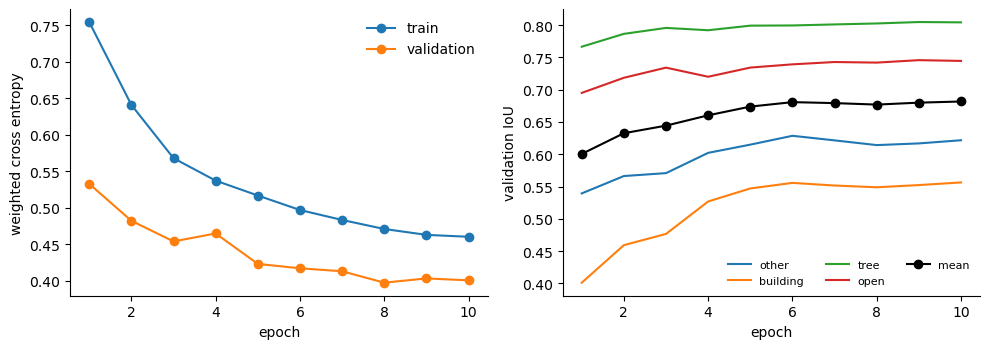

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3.6))
ax[0].plot(log.epoch, log.train_loss, "o-", label="train")
ax[0].plot(log.epoch, log.val_loss, "o-", label="validation")
ax[0].set_xlabel("epoch"); ax[0].set_ylabel("weighted cross entropy"); ax[0].legend(frameon=False)
for c in CLASSES:
    ax[1].plot(log.epoch, log[f"val_iou_{c}"], "-", label=c)
ax[1].plot(log.epoch, log.val_miou, "ko-", label="mean")
ax[1].set_xlabel("epoch"); ax[1].set_ylabel("validation IoU"); ax[1].legend(frameon=False, ncol=3, fontsize=8)
for a in ax:
    a.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.savefig(FIG / "03_training_curve.png", dpi=110)
plt.show()

## Test

- Load the best model by validation mIoU
- Predict every pixel of each test box (512 px windows, 64 px margin), skip 255
- Same scores as the Random Forest
- Save example figures for the Results page

In [8]:
ck = torch.load(MODELS / "unet.pt", weights_only=False)
model.load_state_dict(ck["state"])
print("best epoch", ck["epoch"], "val mIoU", ck["val_miou"])
test = boxes[boxes.role == "test"]
cm = np.zeros((4, 4), np.int64)
cm_by = {s: np.zeros((4, 4), np.int64) for s in ["urban", "suburban", "rural"]}
EX = "42041011700"   # suburban Cumberland box with houses
t1 = time.time()
for _, b in test.iterrows():
    img, lab = load(b.GEOID)
    pred = predict_array(model, img, mean, std, device)
    c = confusion(pred, lab)
    cm += c; cm_by[b.stratum] += c
    if b.GEOID == EX:
        ex = (img, lab, pred)
print(f"test prediction {time.time() - t1:.0f} s")
res = scores(cm)
res["by_group"] = {s: scores(m) for s, m in cm_by.items()}
res["confusion"] = cm.tolist()
res["n_test_pixels"] = int(cm.sum())
res["test_boxes"] = int(len(test))
res["best_epoch"] = int(ck["epoch"]); res["val_miou"] = float(ck["val_miou"])
res["train_minutes"] = round(train_minutes, 1); res["epochs_run"] = int(len(log))
res["n_train_tiles"] = int(len(Xtr)); res["n_val_tiles"] = int(len(data["val"][0]))
res["class_weights"] = class_weights.round(3).tolist()
(OUT / "6950_metrics_unet.json").write_text(json.dumps(res, indent=1))
print(json.dumps({k: res[k] for k in ["iou", "miou", "accuracy"]}, indent=1))

best epoch 10 val mIoU 0.6817


test prediction 34 s
{
 "iou": {
  "other": 0.6012,
  "building": 0.5432,
  "tree": 0.672,
  "open": 0.7753
 },
 "miou": 0.6479,
 "accuracy": 0.8235
}


## Random Forest vs U-Net

- Same test pixels (Cumberland + Centre, label not 255)

In [9]:
rf = json.loads((OUT / "6950_metrics_rf.json").read_text())
comp = pd.DataFrame({"Random Forest": rf["iou"] | {"mean IoU": rf["miou"], "accuracy": rf["accuracy"]},
                     "U-Net": res["iou"] | {"mean IoU": res["miou"], "accuracy": res["accuracy"]}})
comp["gain"] = comp["U-Net"] - comp["Random Forest"]
print(comp.round(3).to_string())
by = pd.DataFrame({f"{m} {s}": d["by_group"][s]["miou"] for m, d in [("RF", rf), ("U-Net", res)] for s in ["urban", "suburban", "rural"]}, index=["mIoU"]).T
print(by.to_string())

          Random Forest  U-Net   gain
other             0.321  0.601  0.280
building          0.267  0.543  0.277
tree              0.368  0.672  0.304
open              0.485  0.775  0.290
mean IoU          0.360  0.648  0.288
accuracy          0.571  0.824  0.252
                  mIoU
RF urban        0.3218
RF suburban     0.3579
RF rural        0.3883
U-Net urban     0.5880
U-Net suburban  0.6813
U-Net rural     0.6720


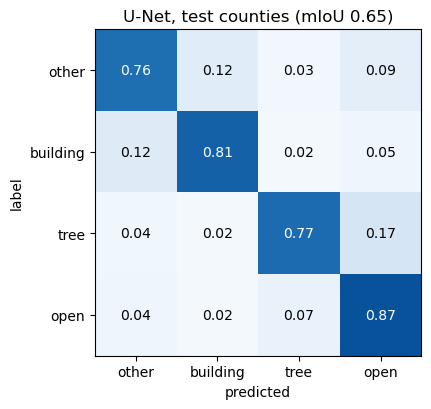

In [10]:
cmn = cm / cm.sum(1, keepdims=True)
fig, ax = plt.subplots(figsize=(4.8, 4.2))
ax.imshow(cmn, cmap="Blues", vmin=0, vmax=1)
for i in range(4):
    for j in range(4):
        ax.text(j, i, f"{cmn[i, j]:.2f}", ha="center", va="center", color="white" if cmn[i, j] > 0.5 else "black")
ax.set_xticks(range(4), CLASSES); ax.set_yticks(range(4), CLASSES)
ax.set_xlabel("predicted"); ax.set_ylabel("label")
ax.set_title(f"U-Net, test counties (mIoU {res['miou']:.2f})")
plt.tight_layout()
plt.savefig(FIG / "03_unet_confusion.png", dpi=110)
plt.show()

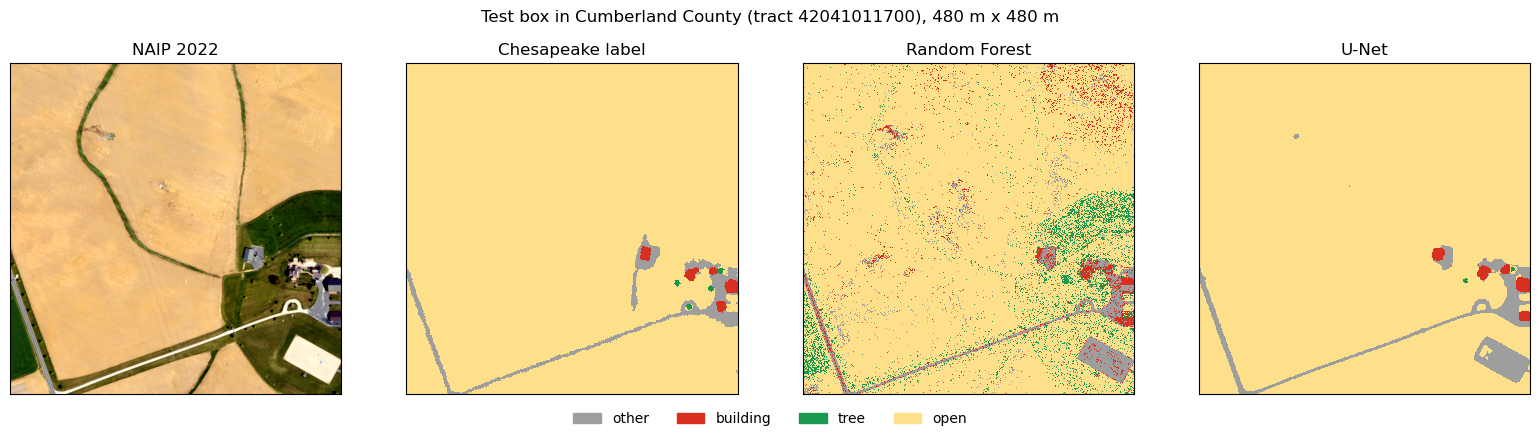

In [11]:
cmap = ListedColormap(["#9e9e9e", "#d7301f", "#1a9850", "#fee08b"])
img, lab, pred = ex
rfp = np.load(OUT / "6950_rf_test_pred.npz")[EX] if (OUT / "6950_rf_test_pred.npz").exists() else None
sl = (slice(600, 1400), slice(600, 1400))   # zoom 480 m x 480 m
rgb = np.moveaxis(img[:3], 0, -1)[sl].astype(float)
lo, hi = np.percentile(rgb, [2, 98])
panels = [("NAIP 2022", None), ("Chesapeake label", lab[sl])] + ([("Random Forest", rfp[sl])] if rfp is not None else []) + [("U-Net", pred[sl])]
fig, axes = plt.subplots(1, len(panels), figsize=(4 * len(panels), 4.3))
for a, (t, arr) in zip(axes, panels):
    if arr is None:
        a.imshow(np.clip((rgb - lo) / (hi - lo), 0, 1))
    else:
        a.imshow(np.ma.masked_equal(arr, 255), cmap=cmap, vmin=0, vmax=3, interpolation="nearest")
    a.set_title(t); a.set_xticks([]); a.set_yticks([])
fig.legend([plt.Rectangle((0, 0), 1, 1, color=c) for c in cmap.colors], CLASSES, loc="lower center", ncol=4, frameon=False)
fig.suptitle(f"Test box in Cumberland County (tract {EX}), 480 m x 480 m", y=0.99)
plt.tight_layout(rect=(0, 0.06, 1, 0.97))
plt.savefig(FIG / "03_example_prediction.png", dpi=110)
plt.show()